# Лабораторная работа 2. Сравнение инструментов обработки данных

*Выполнил студент группы МОАм-251 Аношин Антон.*

Беру те же ДТП, что и в первой работе. Считаю аварии, погибших, раненых и среднее число машин по региону, часу и дню недели. Сравниваю Pandas, Dask, Spark, Polars и DuckDB.

## Часть 1. Окружение и данные

Весь код теперь в этом блокноте, зависимости - в `requirements.txt`. Для Spark нужна Java 17+: путь можно задать через `LAB2_JAVA_HOME`. Данные беру из `data/`, временные файлы складываю в `_work/lab_02/`.

In [1]:
import hashlib, importlib.util, json, os, random
import subprocess, sys, threading, tempfile, time
from pathlib import Path
import numpy as np
import pandas as pd
import psutil
import pyarrow as pa
import pyarrow.parquet as pq
import cloudpickle
KEYS = ["reg_code", "hour", "weekday"]
VALUES = ["dead_n", "injured_n", "vehicles_n"]
COLS = KEYS + VALUES
RESULT = KEYS + ["accidents", "dead", "injured", "vehicles_mean"]
GIB = 1024**3
WORKERS = 4

import platform
import importlib.metadata as metadata
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'requirements.txt').is_file() and (p / 'lab_02').is_dir())
DATA_DIR = Path(os.environ.get('DTP_DATA_DIR', str(ROOT / 'data'))).resolve()
WORK = Path(os.environ.get('LAB2_WORK_DIR', str(ROOT / '_work/lab_02'))).resolve()
WORK.mkdir(parents=True, exist_ok=True)
REPEATS = int(os.environ.get('LAB2_REPEATS', '3'))
assert REPEATS >= 1
sns.set_theme(style='whitegrid')
plt.rcParams.update({'figure.dpi': 110, 'figure.figsize': (10, 4)})
versions = {name: metadata.version(name) for name in
            ['pandas', 'dask', 'pyspark', 'polars', 'duckdb', 'pyarrow', 'great-expectations', 'psutil']}
display(pd.Series(versions, name='версия').to_frame())
print(platform.platform(), platform.python_version())
print(f'CPU: {psutil.cpu_count(logical=False)} физических / {psutil.cpu_count()} логических; '
      f'RAM: {psutil.virtual_memory().total / GIB:.1f} ГиБ; лимит рабочих потоков: {WORKERS}')

,версия
pandas,2.3.3
dask,2026.8.0
pyspark,4.0.5
polars,2.1.0
duckdb,1.5.6
pyarrow,23.0.1
great-expectations,1.24.1
psutil,7.2.2


Windows-11-10.0.26200-SP0 3.13.11
CPU: 6 физических / 12 логических; RAM: 31.6 ГиБ; лимит рабочих потоков: 4


### Вспомогательные функции

Здесь подготовка данных, замеры и графики. Ниже остаются только вызовы.

In [ ]:
def canonical(frame):
    frame = frame[RESULT].sort_values(KEYS).reset_index(drop=True)
    frame[RESULT[:-1]] = frame[RESULT[:-1]].astype("int64")
    frame["vehicles_mean"] = frame["vehicles_mean"].astype("float64")
    return frame

def pandas_query(frame):
    return frame.groupby(KEYS, observed=True, sort=False).agg(
        accidents=("dead_n", "size"), dead=("dead_n", "sum"),
        injured=("injured_n", "sum"), vehicles_mean=("vehicles_n", "mean")
    ).reset_index()

def prepare(data_dir, work):
    import polars as pl

    files = sorted(Path(data_dir).glob("clean/accidents/year=*/part.parquet"))
    if not files:
        raise FileNotFoundError("Нет clean/accidents: сначала загрузите данные ЛР-1")
    scan = pl.scan_parquet(files, hive_partitioning=False).select("accident_id", "dt", *COLS)
    initial = scan.collect()
    unique = initial.unique(subset="accident_id", keep="first", maintain_order=True)
    nonnull = unique.drop_nulls(["accident_id", "dt", *COLS])
    valid = nonnull.filter(
        pl.col("hour").is_between(0, 23) & pl.col("weekday").is_between(0, 6)
        & (pl.col("reg_code") > 0) & (pl.col("dead_n") >= 0)
        & (pl.col("injured_n") >= 0) & (pl.col("vehicles_n") >= 0)
    )
    report = {
        "source_rows": initial.height, "duplicate_ids_removed": initial.height - unique.height,
        "missing_removed": unique.height - nonnull.height,
        "invalid_removed": nonnull.height - valid.height, "clean_rows": valid.height,
        "source_parquet_bytes": sum(f.stat().st_size for f in files),
        "missing_by_column": dict(zip(initial.columns, initial.null_count().row(0))),
    }
    table = valid.select(pl.col(c).cast(pl.Int64) for c in COLS).to_arrow().combine_chunks()
    if not table.num_rows:
        raise ValueError("После очистки нет данных")
    # Без validity bitmap фиксированная ширина - ровно 48 байт на строку.
    table = pa.table({c: pa.array(table[c].to_numpy(), type=pa.int64()) for c in COLS})
    fingerprint = hashlib.sha256(json.dumps([
        (str(f.resolve()), f.stat().st_size, f.stat().st_mtime_ns) for f in files
    ]).encode()).hexdigest()
    config = {"version": 1, "source": fingerprint, "columns": COLS}
    datasets = work / "datasets"
    datasets.mkdir(parents=True, exist_ok=True)
    manifest_path = datasets / "manifest.json"
    if manifest_path.exists():
        saved = json.loads(manifest_path.read_text(encoding="utf-8"))
        if saved["config"] == config and all(
            len(list(Path(d["path"]).glob("*.parquet"))) == d["files"] for d in saved["datasets"]
        ):
            return table, report, saved["datasets"]
    descriptions = []
    targets = [("native", table.num_rows), ("100MiB", (100 * 2**20) // 48), ("1GiB", GIB // 48)]
    for name, count in targets:
        folder = datasets / name
        folder.mkdir(exist_ok=True)
        if any(folder.iterdir()):
            raise FileExistsError(f"Параметры данных изменились; задайте новый LAB2_WORK_DIR вместо {folder}")
        offset, part, logical_bytes = 0, 0, 0
        while offset < count:
            length = min(250_000, count - offset)
            indices = np.arange(offset, offset + length, dtype=np.int64) % table.num_rows
            batch = table.take(pa.array(indices))
            # Пересоздание массивов убирает bitmap, добавленный Arrow take.
            batch = pa.table({c: pa.array(batch[c].to_numpy(), type=pa.int64()) for c in COLS})
            pq.write_table(batch, folder / f"part-{part:04d}.parquet", compression="snappy", use_dictionary=True)
            logical_bytes += batch.nbytes
            offset += length
            part += 1
        descriptions.append({
            "dataset": name, "path": str(folder.resolve()), "rows": count, "files": part,
            "logical_bytes": logical_bytes, "disk_bytes": sum(f.stat().st_size for f in folder.glob("*.parquet")),
            "source_multiplicity": count / table.num_rows,
        })
    manifest_path.write_text(json.dumps({"config": config, "datasets": descriptions}, indent=2), encoding="utf-8")
    return table, report, descriptions

def check_quality(table):
    import great_expectations as gx
    context = gx.get_context(mode='ephemeral')
    source = context.data_sources.add_pandas('lab02')
    asset = source.add_dataframe_asset('accidents')
    batch_def = asset.add_batch_definition_whole_dataframe('clean')
    batch = batch_def.get_batch(batch_parameters={'dataframe': table.to_pandas()})
    suite = gx.ExpectationSuite(name='lab02_quality')
    for c in COLS:
        suite.add_expectation(gx.expectations.ExpectColumnValuesToNotBeNull(column=c))
    for c, low, high in [('reg_code', 1, None), ('hour', 0, 23), ('weekday', 0, 6),
                          ('dead_n', 0, None), ('injured_n', 0, None), ('vehicles_n', 0, None)]:
        suite.add_expectation(gx.expectations.ExpectColumnValuesToBeBetween(column=c, min_value=low, max_value=high))
    suite.add_expectation(gx.expectations.ExpectTableRowCountToEqual(value=table.num_rows))
    validation = batch.validate(suite)
    gx_report = pd.DataFrame([{'проверка': r.expectation_config.type,
                              'колонка': r.expectation_config.kwargs.get('column', 'вся таблица'),
                              'успех': r.success, 'нарушений': r.result.get('unexpected_count', 0)}
                             for r in validation.results])
    assert validation.success
    return gx_report

In [ ]:
class Profile:
    """RSS и счётчики дерева процессов, включая JVM; интервал опроса 20 мс."""

    def snapshot(self):
        processes = [self.process, *self.process.children(recursive=True)]
        rss = 0
        for process in processes:
            try:
                with process.oneshot():
                    key = (process.pid, process.create_time())
                    cpu = process.cpu_times()
                    io = process.io_counters()
                    counters = np.array([cpu.user + cpu.system, io.read_count, io.write_count,
                                         io.read_bytes, io.write_bytes], dtype=float)
                    rss += process.memory_info().rss
                if key not in self.start:
                    self.start[key] = counters.copy() if not self.started else np.zeros(5)
                self.end[key] = counters
            except (psutil.NoSuchProcess, psutil.AccessDenied):
                continue
        self.peak = max(self.peak, rss)
        return rss

    def __enter__(self):
        self.process = psutil.Process()
        self.start, self.end = {}, {}
        self.peak = 0
        self.started = False
        self.baseline = self.snapshot()
        self.started = True
        self.stop = threading.Event()
        self.thread = threading.Thread(target=self.poll, daemon=True)
        self.t0 = time.perf_counter()
        self.thread.start()
        return self

    def poll(self):
        while not self.stop.wait(0.02):
            self.snapshot()

    def __exit__(self, *exc):
        self.elapsed = time.perf_counter() - self.t0
        self.stop.set()
        self.thread.join()
        self.snapshot()
        totals = sum((self.end[k] - v for k, v in self.start.items()), np.zeros(5))
        self.metrics = dict(zip(["cpu_s", "read_ops", "write_ops", "read_bytes", "write_bytes"], totals.tolist()))
        self.metrics.update(seconds=self.elapsed, peak_rss_mib=self.peak / 2**20,
                            rss_delta_mib=max(0, self.peak - self.baseline) / 2**20,
                            baseline_rss_mib=self.baseline / 2**20,
                            cpu_percent=totals[0] / self.elapsed * 100)

def java_environment(env):
    if env.get("LAB2_JAVA_HOME"):
        env["JAVA_HOME"] = env["LAB2_JAVA_HOME"]
    elif os.name == "nt":
        # Переносимая Java, если она подготовлена в каталоге OpenCode.
        root = Path.home() / "AppData/Local/Temp/opencode/lab02-java17"
        candidates = sorted(root.glob("*/bin/java.exe"))
        if candidates:
            env["JAVA_HOME"] = str(candidates[-1].parents[1])
    if os.name == "nt" and not env.get("SPARK_HOME"):
        spark_home = Path(importlib.util.find_spec("pyspark").origin).parent
        if not str(spark_home).isascii():
            # .cmd-лаунчер Spark и кириллица в пути: ASCII junction без копирования JAR.
            suffix = hashlib.sha256(str(spark_home).encode()).hexdigest()[:12]
            junction = Path(tempfile.gettempdir()) / f"lab02-spark-{suffix}"
            if not junction.exists():
                command = ("New-Item -ItemType Junction -Path '" + str(junction).replace("'", "''")
                           + "' -Target '" + str(spark_home).replace("'", "''") + "' | Out-Null")
                completed = subprocess.run(["powershell", "-NoProfile", "-Command", command], capture_output=True)
                if completed.returncode and not junction.exists():
                    raise RuntimeError("Не удалось создать ASCII junction для Spark: "
                                       + completed.stderr.decode(errors="replace"))
            env["SPARK_HOME"] = str(junction)
    env.update({"SPARK_LOCAL_IP": "127.0.0.1", "PYSPARK_PYTHON": sys.executable,
                "PYTHONUTF8": "1", "POLARS_MAX_THREADS": str(WORKERS),
                "OMP_NUM_THREADS": "1", "OPENBLAS_NUM_THREADS": "1", "NUMEXPR_NUM_THREADS": "1"})
    return env

In [ ]:
def spark_session():
    from pyspark.sql import SparkSession
    from pyspark.sql import functions as F

    spark = (SparkSession.builder.master(f"local[{WORKERS}]").appName("BigDataLab2")
             .config("spark.driver.memory", "4g").config("spark.ui.enabled", "true")
             .config("spark.sql.shuffle.partitions", "200")
             .config("spark.default.parallelism", str(WORKERS))
             .config("spark.sql.adaptive.enabled", "false")
             .config("spark.sql.parquet.enableVectorizedReader", "true")
             .config("spark.sql.session.timeZone", "UTC")
             .config("spark.driver.host", "127.0.0.1").getOrCreate())
    spark.sparkContext.setLogLevel("ERROR")
    spark.range(1000).agg(F.sum("id")).collect()
    return spark

def spark_query(frame, variant="baseline", hot_reg=None):
    from pyspark.sql import functions as F

    if variant == "salted":
        salted = frame.withColumn("salt", F.when(
            F.col("reg_code") == F.lit(hot_reg),
            F.pmod(F.xxhash64(F.monotonically_increasing_id()), F.lit(8))
        ).otherwise(F.lit(0)))
        partial = salted.groupBy(*KEYS, "salt").agg(
            F.count("*").alias("n"), F.sum("dead_n").alias("d"),
            F.sum("injured_n").alias("i"), F.sum("vehicles_n").alias("v"))
        return partial.groupBy(*KEYS).agg(
            F.sum("n").alias("accidents"), F.sum("d").alias("dead"),
            F.sum("i").alias("injured"), (F.sum("v") / F.sum("n")).alias("vehicles_mean"))
    if variant == "repartition":
        frame = frame.repartition(16, *KEYS)
    return frame.groupBy(*KEYS).agg(
        F.count("*").alias("accidents"), F.sum("dead_n").alias("dead"),
        F.sum("injured_n").alias("injured"), F.avg("vehicles_n").alias("vehicles_mean"))

def spark_stages(spark):
    import urllib.request

    url = f"{spark.sparkContext.uiWebUrl}/api/v1/applications/{spark.sparkContext.applicationId}/stages"
    with urllib.request.urlopen(url, timeout=15) as response:
        return json.load(response)

def stage_report(spark, before):
    import urllib.request

    stages = [s for s in spark_stages(spark) if s["stageId"] not in before and s["status"] == "COMPLETE"]
    reports = []
    for stage in stages:
        url = (f"{spark.sparkContext.uiWebUrl}/api/v1/applications/{spark.sparkContext.applicationId}"
               f"/stages/{stage['stageId']}/{stage['attemptId']}/taskList?length=10000")
        with urllib.request.urlopen(url, timeout=15) as response:
            tasks = json.load(response)
        durations = [t.get("duration", 0) for t in tasks if t.get("status") == "SUCCESS"]
        reports.append({**{k: stage.get(k, 0) for k in [
            "stageId", "numTasks", "inputBytes", "shuffleReadBytes", "shuffleWriteBytes", "executorRunTime"]},
            "task_median_ms": float(np.median(durations)) if durations else None,
            "task_max_ms": max(durations) if durations else None,
        })
    return reports

def worker(spec):
    tool, variant = spec["tool"], spec.get("variant", "baseline")
    folder = Path(spec["path"])
    files = sorted(folder.glob("*.parquet"))
    if not files:
        raise FileNotFoundError(folder)
    if tool == "pandas" and spec["logical_bytes"] > GIB:
        raise ValueError("Защитный лимит эксперимента: pandas не получает более 1 ГиБ")
    if tool == "pandas" and spec["logical_bytes"] * 5 > psutil.virtual_memory().available:
        raise MemoryError("Недостаточно свободной RAM для pandas с пятикратным запасом")
    pa.set_cpu_count(WORKERS)
    startup = time.perf_counter()
    spark = None
    extras = {}
    if tool == "dask":
        import dask
        import dask.dataframe as dd
        dask.config.set(scheduler="threads", num_workers=WORKERS)
        dd.from_pandas(pd.DataFrame({c: [1] for c in COLS}), npartitions=1).groupby(KEYS).size().compute()
    elif tool == "polars":
        import polars as pl
        pl.DataFrame({c: [1] for c in COLS}).group_by(KEYS).len()
    elif tool == "duckdb":
        import duckdb
        connection = duckdb.connect(config={"threads": WORKERS, "memory_limit": "4GB"})
        connection.execute("SELECT sum(i) FROM range(1000) t(i)").fetchall()
    elif tool == "spark":
        spark = spark_session()
        spark.conf.set("spark.sql.shuffle.partitions", "16" if variant in {"shuffle16", "combined"} else "200")
        spark.conf.set("spark.sql.adaptive.enabled", str(variant in {"aqe", "combined"}).lower())
        before = {s["stageId"] for s in spark_stages(spark)}
        extras["config"] = dict(spark.sparkContext.getConf().getAll())
        extras["sql_config"] = {k: spark.conf.get(k) for k in [
            "spark.sql.shuffle.partitions", "spark.sql.adaptive.enabled"]}
    elif tool != "pandas":
        raise ValueError(tool)
    else:
        pandas_query(pd.DataFrame({c: [1] for c in COLS}))
    startup_s = time.perf_counter() - startup

    with Profile() as profile:
        if tool == "pandas":
            frame = pq.ParquetDataset(files).read(columns=COLS).to_pandas()
            result = pandas_query(frame)
        elif tool == "dask":
            frame = dd.read_parquet(str(folder), columns=COLS)
            result = frame.groupby(KEYS).agg(
                {"dead_n": ["count", "sum"], "injured_n": "sum", "vehicles_n": "mean"},
                split_out=16).compute().reset_index()
            result.columns = RESULT
        elif tool == "polars":
            result = pl.scan_parquet(str(folder / "*.parquet")).group_by(KEYS).agg(
                pl.len().cast(pl.Int64).alias("accidents"), pl.col("dead_n").sum().alias("dead"),
                pl.col("injured_n").sum().alias("injured"),
                pl.col("vehicles_n").mean().alias("vehicles_mean")
            ).collect().to_pandas()
        elif tool == "duckdb":
            result = connection.execute('''
                SELECT reg_code, hour, weekday, count(*) AS accidents,
                       sum(dead_n)::BIGINT AS dead, sum(injured_n)::BIGINT AS injured,
                       avg(vehicles_n) AS vehicles_mean
                FROM read_parquet(?) GROUP BY reg_code, hour, weekday
            ''', [str(folder / "*.parquet")]).fetchdf()
        else:
            # Явный список файлов обходит Windows NativeIO при listStatus каталога.
            query = spark_query(spark.read.parquet(*[f.as_posix() for f in files]), variant, spec.get("hot_reg"))
            result = pd.DataFrame([r.asDict() for r in query.collect()], columns=RESULT)

    if spark:
        extras["stages"] = stage_report(spark, before)
        extras["plan"] = query._jdf.queryExecution().executedPlan().toString()
        extras["formatted_plan"] = spark._jvm.PythonSQLUtils.explainString(query._jdf.queryExecution(), "formatted")
    output = Path(spec["output"])
    canonical(result).to_parquet(output.with_suffix(".parquet"), index=False)
    output.write_text(json.dumps({**spec, **profile.metrics, "startup_s": startup_s,
                                  "result_groups": len(result), **extras}, ensure_ascii=False, indent=2), encoding="utf-8")
    if spark:
        spark.stop()

In [ ]:
def run_case(dataset, tool, work, repeat=0, variant="baseline", hot_reg=None):
    label = f"{dataset['dataset']}-{tool}-{variant}-{repeat}"
    output = work / "runs" / f"{label}.json"
    output.parent.mkdir(parents=True, exist_ok=True)
    spec = {**dataset, "tool": tool, "variant": variant, "repeat": repeat,
            "hot_reg": hot_reg, "output": str(output.resolve())}
    request = output.with_suffix(".request.json")
    request.write_text(json.dumps(spec), encoding="utf-8")
    started = time.perf_counter()
    with output.with_suffix(".log").open("w", encoding="utf-8") as log:
        completed = subprocess.run([sys.executable, "-c",
                                    "import cloudpickle,json,sys; "
                                    "f=cloudpickle.load(open(sys.argv[1],'rb')); "
                                    "f(json.load(open(sys.argv[2],encoding='utf-8')))",
                                    str(WORKER_PAYLOAD), str(request)],
                                   env=java_environment(os.environ.copy()), stdout=log, stderr=log, timeout=600)
    if completed.returncode:
        tail = output.with_suffix(".log").read_text(encoding="utf-8", errors="replace")[-6000:]
        raise RuntimeError(f"{label}: процесс завершился с ошибкой\n{tail}")
    measurement = json.loads(output.read_text(encoding="utf-8"))
    measurement["wall_including_startup_s"] = time.perf_counter() - started
    return measurement

def expected_result(table, dataset):
    # Точное ожидание для циклически повторённой истории, включая последний неполный цикл.
    count, base_n = dataset["rows"], table.num_rows
    full, rest = divmod(count, base_n)
    parts = []
    for source, multiplier in [(table, full), (table.slice(0, rest), 1)]:
        if multiplier == 0 or not source.num_rows:
            continue
        frame = source.to_pandas()
        group = frame.groupby(KEYS).agg(n=("dead_n", "size"), dead=("dead_n", "sum"),
                                       injured=("injured_n", "sum"), vehicles_sum=("vehicles_n", "sum"))
        parts.append(group * multiplier)
    total = pd.concat(parts).groupby(level=KEYS).sum().reset_index()
    total["vehicles_mean"] = total["vehicles_sum"] / total["n"]
    return canonical(total.rename(columns={"n": "accidents"}))

def verify(measurement, expected):
    actual = pd.read_parquet(Path(measurement["output"]).with_suffix(".parquet"))
    pd.testing.assert_frame_equal(canonical(actual), expected, check_exact=False, rtol=1e-10, atol=1e-12)

def run_benchmarks(datasets, table, work, repeats=3,
                   tools=("pandas", "dask", "spark", "polars", "duckdb"),
                   variants=("baseline",), hot_reg=None, seed=42):
    expected = {d["dataset"]: expected_result(table, d) for d in datasets}
    jobs = [(d, tool, variant, r) for r in range(repeats) for d in datasets
            for tool in tools for variant in variants]
    random.Random(seed).shuffle(jobs)
    measurements = []
    for i, (dataset, tool, variant, repeat) in enumerate(jobs, 1):
        print(f"[{i}/{len(jobs)}] {dataset['dataset']}: {tool}, {variant}, повтор {repeat + 1}", flush=True)
        result = run_case(dataset, tool, work, repeat, variant, hot_reg)
        verify(result, expected[dataset["dataset"]])
        result["verified"] = True
        measurements.append(result)
    return measurements

def summarize(measurements):
    metrics = pd.DataFrame(measurements).drop(
        columns=["stages", "config", "sql_config", "plan", "formatted_plan"], errors="ignore")
    assert metrics.verified.all()
    groups = metrics.groupby(["dataset", "tool"])
    columns = ["seconds", "peak_rss_mib", "rss_delta_mib", "cpu_s", "cpu_percent",
               "read_ops", "write_ops", "read_bytes", "write_bytes", "startup_s", "wall_including_startup_s"]
    summary = groups[columns].median().assign(minimum_s=groups.seconds.min(), maximum_s=groups.seconds.max())
    return metrics, summary

def summarize_spark(runs):
    optimization = pd.DataFrame([{'variant': m['variant'], 'seconds': m['seconds'],
                                  'peak_rss_mib': m['peak_rss_mib'], 'cpu_s': m['cpu_s'],
                                  'shuffle_MiB': sum(s['shuffleWriteBytes'] for s in m['stages'])/2**20,
                                  'tasks': sum(s['numTasks'] for s in m['stages'])}
                                 for m in runs]).groupby('variant').median()
    optimization['speedup'] = optimization.loc['baseline','seconds'] / optimization.seconds
    optimization['time_saved_percent'] = (1-optimization.seconds/optimization.loc['baseline','seconds'])*100
    return optimization

In [ ]:
def show_data(table, cleaning, datasets):
    display(pd.Series({k: v for k, v in cleaning.items() if k != 'missing_by_column'}, name='строк / байт').to_frame())
    display(pd.Series(cleaning['missing_by_column'], name='пропуски до очистки').to_frame())
    sizes = pd.DataFrame(datasets).set_index('dataset')
    display(sizes.assign(decoded_MiB=sizes.logical_bytes / 2**20, parquet_MiB=sizes.disk_bytes / 2**20)
            [['rows', 'files', 'decoded_MiB', 'parquet_MiB', 'source_multiplicity']].round(3))
    assert cleaning['clean_rows'] == table.num_rows
    assert table.nbytes == table.num_rows * 48
    assert sizes.loc['1GiB', 'logical_bytes'] <= GIB
    return sizes

def plot_comparison(summary, sizes):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    for tool in summary.index.get_level_values('tool').unique():
        values = summary.xs(tool, level='tool').join(sizes[['logical_bytes']]).sort_values('logical_bytes')
        x = values.logical_bytes / 2**20
        axes[0].plot(x, values.seconds, 'o-', label=tool)
        axes[1].plot(x, values.peak_rss_mib, 'o-', label=tool)
    axes[0].set(xlabel='декодированный вход, МиБ', ylabel='медиана времени, с', title='Время vs объём')
    axes[1].set(xlabel='декодированный вход, МиБ', ylabel='пиковая RSS дерева процессов, МиБ', title='RAM vs объём')
    for ax in axes:
        ax.legend()
    plt.tight_layout(); plt.show()

def show_plan(measurement):
    print(measurement['formatted_plan'])
    stages = pd.DataFrame(measurement['stages'])
    display(stages)
    print(f'Фактически завершённых stages запроса: {len(stages)}; задач: {stages.numTasks.sum()}')
    print(f'Shuffle write/read: {stages.shuffleWriteBytes.sum()/2**20:.3f} / '
          f'{stages.shuffleReadBytes.sum()/2**20:.3f} МиБ')
    print(f'Чтение Parquet по метрикам Spark: {stages.inputBytes.sum()/2**20:.3f} МиБ')
    print('Количество Exchange в плане:', measurement['plan'].count('Exchange'))
    return stages

def show_skew(table, stages):
    native_df = table.to_pandas()
    region_counts = native_df.groupby('reg_code').size().sort_values(ascending=False)
    key_counts = native_df.groupby(KEYS).size().sort_values(ascending=False)
    hot_reg = int(region_counts.index[0])
    display(pd.DataFrame([{'уровень': name, 'ключей': len(s), 'CV': s.std(ddof=0)/s.mean(),
                           'max/median': s.max()/s.median(), 'доля top-1': s.max()/s.sum()}
                          for name, s in [('регион', region_counts), ('полный ключ', key_counts)]]).round(3))
    region_counts.head(20).plot.bar(title='Число ДТП: 20 наиболее частых регионов', ylabel='ДТП', xlabel='код региона')
    plt.tight_layout(); plt.show()
    display(key_counts.head(10).rename('строк').to_frame())
    task_imbalance = stages[['stageId', 'numTasks', 'task_median_ms', 'task_max_ms']].copy()
    task_imbalance['max/median времени'] = task_imbalance.task_max_ms / task_imbalance.task_median_ms.replace(0, np.nan)
    display(task_imbalance.round(2))
    return hot_reg

def show_optimizations(optimization, runs):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    optimization.speedup.plot.bar(ax=axes[0], ylabel='ускорение к baseline', title='Эффект каждой оптимизации')
    axes[0].axhline(1, color='black', ls='--')
    axes[1].scatter(optimization.shuffle_MiB, optimization.seconds, s=80)
    for name, row in optimization.iterrows():
        axes[1].annotate(name, (row.shuffle_MiB, row.seconds), xytext=(4, 4), textcoords='offset points')
    axes[1].set(xlabel='shuffle write, МиБ (затраты обмена)', ylabel='время, с', title='Затраты vs выгода')
    plt.tight_layout(); plt.show()
    best_variant = optimization.seconds.idxmin()
    print('Лучшая измеренная конфигурация:', best_variant)
    print('Это минимум среди проверенных вариантов, а не доказанный глобальный оптимум.')
    chosen = next(m for m in runs if m['variant'] == best_variant)
    display(pd.Series(chosen['sql_config'], name='параметр').to_frame())
    print('Дополнительное преобразование:', best_variant if best_variant in ['salted','repartition'] else 'без salting/repartition')
    show_plan(chosen)
    return best_variant

def show_cpu_comparison(summary):
    track_a = summary.loc[(summary.index.get_level_values('dataset').isin(['100MiB','1GiB'])) &
                          (summary.index.get_level_values('tool').isin(['pandas','polars','duckdb'])),
                         ['seconds','peak_rss_mib','rss_delta_mib']]
    display(track_a.unstack('dataset').round(3))
    for name in ['100MiB', '1GiB']:
        base = summary.loc[(name, 'pandas'), 'seconds']
        print(name)
        for tool in ['polars', 'duckdb']:
            value = summary.loc[(name, tool), 'seconds']
            print(f'  {tool}: {base/value:.2f}x; снижение времени {(1-value/base)*100:+.1f}%')

def choice_matrix():
    matrix = pd.DataFrame([
        ['Данные помещаются в RAM, разовый анализ', '+++', '++', '+', '+++', '+++', 'pandas / Polars / DuckDB'],
        ['Один узел, чтение с диска и SQL', '++', '++', '+', '+++', '+++', 'DuckDB / Polars'],
        ['Больше RAM одного процесса, Python-пайплайн', '+', '+++', '++', '++', '++', 'Dask, после проверки spilling/разбиения'],
        ['Десятки ГБ+, распределённый ETL и отказоустойчивость', '+', '++', '+++', '++', '++', 'Spark, если нужен кластер'],
        ['Малые короткие запросы', '+++', '++', '+', '+++', '+++', 'CPU, без GPU'],
        ['50 ГБ+, NVIDIA, поддерживаемые SQL-операции', '+', '++', '+++', '++', '++', 'Spark + GPU только после измерений'],
    ], columns=['условие', 'Pandas', 'Dask', 'Spark', 'Polars', 'DuckDB', 'рекомендация'])
    return matrix

def estimate_cost(summary, rows):
    PRICE_CPU_HOUR = 20.0  # ₽/час: учебное допущение для одинаковой 4-vCPU машины
    DEVELOPER_HOUR = 1500.0
    development = {'pandas': 4, 'dask': 8, 'spark': 12, 'polars': 5, 'duckdb': 4}
    maintenance = {'pandas': 1, 'dask': 2, 'spark': 4, 'polars': 1, 'duckdb': 1}
    economics = summary.xs('1GiB')[['seconds']].copy()
    economics['compute_RUB_run'] = economics.seconds / 3600 * PRICE_CPU_HOUR
    economics['million_rows_per_second'] = rows / 1e6 / economics.seconds
    economics['RUB_per_million_rows'] = economics.compute_RUB_run / (rows/1e6)
    economics['development_hours'] = pd.Series(development)
    economics['maintenance_hours_month'] = pd.Series(maintenance)
    economics['first_year_RUB'] = (economics.compute_RUB_run * 365 + economics.development_hours * DEVELOPER_HOUR
                                    + economics.maintenance_hours_month * 12 * DEVELOPER_HOUR)

    return economics

WORKER_PAYLOAD = WORK / 'worker.pkl'
with WORKER_PAYLOAD.open('wb') as stream:
    cloudpickle.dump(worker, stream)

### 1.1. Очистка и размер срезов

Убираю дубли, пропуски и неверные значения в нужных полях. Для тестов на 100 МиБ и 1 ГиБ повторяю историю ДТП - это нагрузочные копии, не новые события. Размер считаю после распаковки Arrow; исходную историю проверяю отдельно.

In [2]:
table, cleaning, datasets = prepare(DATA_DIR, WORK)
sizes = show_data(table, cleaning, datasets)

,строк / байт
source_rows,1738125
duplicate_ids_removed,0
missing_removed,0
invalid_removed,0
clean_rows,1738125
source_parquet_bytes,90090560


,пропуски до очистки
accident_id,0
dt,0
reg_code,0
hour,0
weekday,0
dead_n,0
injured_n,0
vehicles_n,0


,rows,files,decoded_MiB,parquet_MiB,source_multiplicity
dataset,,,,,
native,1738125,7,79.565,3.194,1.000
100MiB,2184533,9,100.000,3.993,1.257
1GiB,22369621,90,1024.000,41.160,12.870


### 1.2. Great Expectations

Проверяю пропуски, диапазоны значений и число строк во всей очищенной таблице.

In [3]:
gx_report = check_quality(table)
display(gx_report)


Calculating Metrics:   0%|          | 0/63 [00:00<?, ?it/s]


Calculating Metrics:   0%|          | 0/63 [00:00<?, ?it/s]


Calculating Metrics:   3%|▎         | 2/63 [00:00<00:00, 2618.17it/s]


Calculating Metrics:   3%|▎         | 2/63 [00:00<00:00, 1421.08it/s]


Calculating Metrics:   5%|▍         | 3/63 [00:00<00:00, 1505.67it/s]


Calculating Metrics:   5%|▍         | 3/63 [00:00<00:00, 1099.90it/s]

... (4 outputs left out)


Calculating Metrics: 100%|██████████| 63/63 [00:00<00:00, 202.55it/s]


Calculating Metrics: 100%|██████████| 63/63 [00:00<00:00, 202.55it/s]


Calculating Metrics: 100%|██████████| 63/63 [00:00<00:00, 201.07it/s]

,проверка,колонка,успех,нарушений
0,expect_column_values_to_not_be_null,reg_code,True,0
1,expect_column_values_to_be_between,reg_code,True,0
2,expect_column_values_to_not_be_null,hour,True,0
3,expect_column_values_to_be_between,hour,True,0
4,expect_column_values_to_not_be_null,weekday,True,0
5,expect_column_values_to_be_between,weekday,True,0
6,expect_column_values_to_not_be_null,dead_n,True,0
7,expect_column_values_to_be_between,dead_n,True,0
8,expect_column_values_to_not_be_null,injured_n,True,0
9,expect_column_values_to_be_between,injured_n,True,0


**Вывод.** Проверки выбранных полей прошли. Можно переходить к замерам.

## Часть 2. Сравнение производительности

Все инструменты читают одни Parquet-файлы и считают одинаковые показатели. Каждый запускаю трижды в отдельном процессе, результаты сверяю автоматически.

Сравниваю медианы времени, память, CPU и I/O. Прогрев и запуск JVM считаю отдельно, кэш ОС не сбрасываю. Память замеряю вместе с дочерними процессами; I/O здесь - счётчики процессов, а не обращения к SSD.

In [5]:
measurements = run_benchmarks(datasets, table, WORK, repeats=REPEATS)
(WORK / 'measurements.json').write_text(json.dumps(measurements, ensure_ascii=False, indent=2), encoding='utf-8')
metrics, summary = summarize(measurements)
display(summary.round(3))

[1/45] native: polars, повтор 2


[2/45] 100MiB: dask, повтор 2


[3/45] 100MiB: dask, повтор 3


[4/45] 1GiB: pandas, повтор 1


[5/45] 100MiB: polars, повтор 2


[6/45] 100MiB: duckdb, повтор 1


... (36 outputs left out)

[43/45] native: dask, повтор 1


[44/45] 100MiB: spark, повтор 1


[45/45] 1GiB: pandas, повтор 3


seconds  minimum_s  maximum_s  peak_rss_mib  rss_delta_mib  \
dataset tool                                                                 
100MiB  dask      0.310      0.306      0.338       315.672        189.645   
        duckdb    0.043      0.042      0.043       115.656         15.535   
        pandas    0.135      0.134      0.137       381.906        300.637   
        polars    0.033      0.032      0.040       251.855        150.773   
        spark     2.397      2.359      2.411      1075.613        560.102   
1GiB    dask      1.599      1.567      1.625       412.336        286.301   
        duckdb    0.293      0.278      0.297       149.305         48.934   
        pandas    1.115      1.109      1.124      3056.230       2974.820   
        polars    0.180      0.179      0.183       303.266        201.965   
        spark     3.456      3.367      3.528      1641.531       1129.016   
native  dask      0.278      0.274      0.281       317.043        190.941   
        duckdb    0.034      0.032      0.038       107.957          7.730   
        pandas    0.119      0.118      0.124       337.754        256.496   
        polars    0.030      0.029      0.034       231.445        130.133   
        spark     2.398      2.395      2.424      1222.863        705.781   

                 cpu_s  cpu_percent  read_ops  write_ops  read_bytes  \
dataset tool                                                           
100MiB  dask     0.531      171.363     103.0        1.0   5211906.0   
        duckdb   0.141      333.757    1494.0        0.0   4322005.0   
        pandas   0.250      185.532      35.0        0.0   4981401.0   
        polars   0.141      426.233      21.0        0.0   6339975.0   
        spark   11.500      479.841    7047.0     1321.0  14674027.0   
1GiB    dask     4.031      252.120     346.0        1.0  49476669.0   
        duckdb   1.141      405.112   15216.0        0.0  44533470.0   
        pandas   1.750      157.849     197.0        0.0  49144691.0   
        polars   0.766      424.906     182.0        0.0  66167817.0   
        spark   19.094      541.141    8321.0     1723.0  54441433.0   
native  dask     0.469      168.463      97.0        1.0   4242380.0   
        duckdb   0.125      385.143    1178.0        0.0   3455469.0   
        pandas   0.203      171.013      31.0        0.0   4014828.0   
        polars   0.109      320.981      17.0        0.0   4980186.0   
        spark   12.141      506.996    8041.0     1723.0  14179516.0   

                write_bytes  startup_s  wall_including_startup_s  
dataset tool                                                      
100MiB  dask            4.0      0.525                     1.404  
        duckdb          0.0      0.043                     0.571  
        pandas          0.0      0.005                     0.632  
        polars          0.0      0.142                     0.681  
        spark     3400912.0      7.211                    10.764  
1GiB    dask            4.0      0.533                     2.671  
        duckdb          0.0      0.041                     0.816  
        pandas          0.0      0.005                     1.664  
        polars          0.0      0.143                     0.830  
        spark     4672652.0      7.219                    11.746  
native  dask            4.0      0.545                     1.357  
        duckdb          0.0      0.041                     0.568  
        pandas          0.0      0.005                     0.615  
        polars          0.0      0.143                     0.684  
        spark     4085508.0      7.273                    10.754

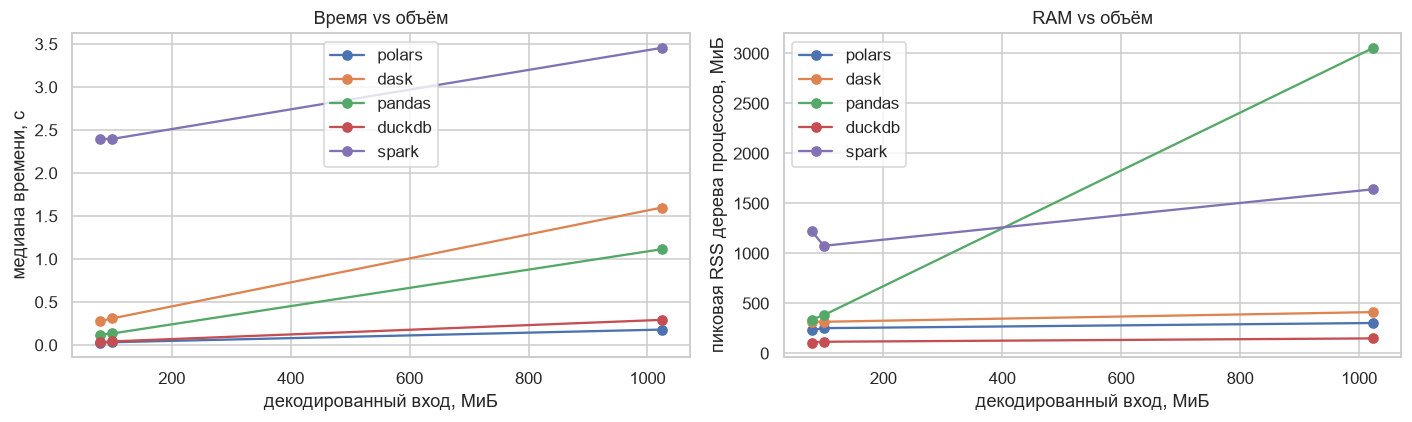

In [6]:
plot_comparison(summary, sizes)

In [7]:
times_1g = summary.xs('1GiB').seconds
speed = pd.DataFrame({'секунд': times_1g, 'ускорение к pandas': times_1g['pandas'] / times_1g,
                      'снижение времени к pandas, %': (1 - times_1g / times_1g['pandas']) * 100})
display(speed.round(3))
print(f'Dask на 1 ГиБ: изменение времени относительно pandas = '
      f'{(1 - times_1g["dask"] / times_1g["pandas"]) * 100:+.1f}% (отрицательное - замедление)')
print('Самый быстрый инструмент на 1 ГиБ:', times_1g.idxmin())
print('Фактически проверенные конфигурации Spark:')
spark_example = next(m for m in measurements if m['tool'] == 'spark' and m['dataset'] == 'native')
display(pd.Series({k: v for k, v in spark_example['config'].items()
                   if k in ['spark.master', 'spark.driver.memory', 'spark.default.parallelism', 'spark.app.name']}
                  | spark_example['sql_config'], name='значение').to_frame())

,секунд,ускорение к pandas,"снижение времени к pandas, %"
tool,,,
dask,1.599,0.697,-43.444
duckdb,0.293,3.803,73.703
pandas,1.115,1.000,0.000
polars,0.180,6.186,83.835
spark,3.456,0.323,-210.025


Dask на 1 ГиБ: изменение времени относительно pandas = -43.4% (отрицательное - замедление)
Самый быстрый инструмент на 1 ГиБ: polars
Фактически проверенные конфигурации Spark:


,значение
spark.app.name,BigDataLab2
spark.default.parallelism,4
spark.master,local[4]
spark.driver.memory,4g
spark.sql.shuffle.partitions,200
spark.sql.adaptive.enabled,false


### 2.2. Ограничение Pandas

Ставлю защитный лимит входа в 1 ГиБ, чтобы случайно не забить память. Это ограничение теста: сам Pandas может обработать и больше, если хватает RAM.

In [8]:
with np.testing.assert_raises_regex(ValueError, '1 ГиБ'):
    worker({**datasets[0], 'tool': 'pandas', 'logical_bytes': GIB + 1})
print('Защитный лимит pandas сработал')

Защитный лимит сработал: Защитный лимит эксперимента: pandas не получает более 1 ГиБ


**Вывод.** На этих данных Dask и Spark медленнее Pandas: накладные расходы пока перевешивают пользу параллелизма.

## Часть 3. Физический план Spark

Смотрю план без AQE, с 200 shuffle partitions. Spark читает Parquet, считает промежуточные итоги, перераспределяет их через `Exchange` и собирает результат.

In [9]:
baseline = next(m for m in measurements if m['tool'] == 'spark' and m['dataset'] == '1GiB')
stages = show_plan(baseline)

== Physical Plan ==
* HashAggregate (5)
+- Exchange (4)
   +- * HashAggregate (3)
      +- * ColumnarToRow (2)
         +- Scan parquet  (1)


(1) Scan parquet 
Output [6]: [reg_code#7L, hour#8L, weekday#9L, dead_n#10L, injured_n#11L, vehicles_n#12L]
Batched: true
Location: InMemoryFileIndex [file:/C:/Users/Anton/Desktop/projects/Уник/2 курс/Современные технологии обработки больших данных/big_data/lab_02/_work/datasets/1GiB/part-0000.parquet, ... 89 entries]
ReadSchema: struct<reg_code:bigint,hour:bigint,weekday:bigint,dead_n:bigint,injured_n:bigint,vehicles_n:bigint>

(2) ColumnarToRow [codegen id : 1]
Input [6]: [reg_code#7L, hour#8L, weekday#9L, dead_n#10L, injured_n#11L, vehicles_n#12L]

(3) HashAggregate [codegen id : 1]
Input [6]: [reg_code#7L, hour#8L, weekday#9L, dead_n#10L, injured_n#11L, vehicles_n#12L]
Keys [3]: [reg_code#7L, hour#8L, weekday#9L]
Functions [4]: [partial_count(1), partial_sum(dead_n#10L), partial_sum(injured_n#11L), partial_avg(vehicles_n#12L)]
Aggregate Attr

,stageId,numTasks,inputBytes,shuffleReadBytes,shuffleWriteBytes,executorRunTime,task_median_ms,task_max_ms
0,5,200,0,1927140,0,1005,8.0,32
1,4,4,43159885,0,1927140,6113,1550.5,1555
2,3,1,0,0,0,174,189.0,189
3,2,90,0,0,0,151,12.0,92


Фактически завершённых stages запроса: 4; задач: 295
Shuffle write/read: 1.838 / 1.838 МиБ
Чтение Parquet по метрикам Spark: 41.160 МиБ
Количество Exchange в плане: 1


**Вывод.** Число stages и объёмы обмена беру из Spark UI. Перед shuffle уже идёт частичная агрегация, поэтому данных передаётся меньше. Дальше проверю, нужны ли здесь 200 разделов.

## Часть 4. Skew

Смотрю, насколько неравномерно распределены регионы и полные ключи. Для ключей считаю CV и max/median, для задач - разброс времени.

,уровень,ключей,CV,max/median,доля top-1
0,регион,86,0.861,7.099,0.058
1,полный ключ,14322,1.078,15.100,0.001


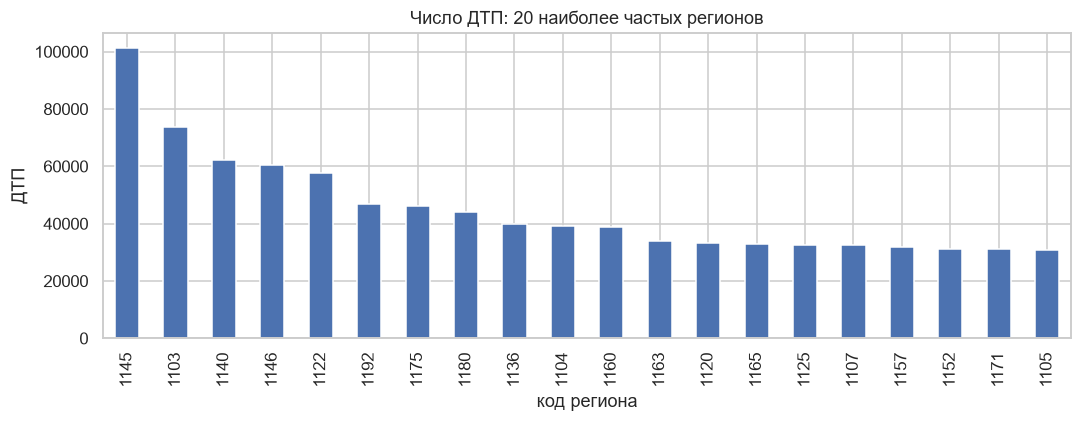

строк
reg_code hour weekday       
1145     18   3         1208
              4         1176
              1         1157
              0         1141
              2         1128
         19   1         1119
              3         1082
              0         1077
         17   0         1073
              4         1070

,stageId,numTasks,task_median_ms,task_max_ms,max/median времени
0,5,200,8.0,32,4.00
1,4,4,1550.5,1555,1.00
2,3,1,189.0,189,1.00
3,2,90,12.0,92,7.67


In [10]:
hot_reg = show_skew(table, stages)

Попробую разбить самый частый регион на восемь групп с «солью», а потом объединить итоги. Среднее считаю через общую сумму и число строк, чтобы не исказить результат.

In [11]:
large = next(d for d in datasets if d['dataset'] == '1GiB')
salted = run_benchmarks([large], table, WORK, repeats=REPEATS, tools=('spark',),
                        variants=('salted',), hot_reg=hot_reg)
baseline_time = float(times_1g['spark'])
salt_time = float(np.median([m['seconds'] for m in salted]))
display(pd.DataFrame({'вариант': ['baseline', 'salting'], 'время, с': [baseline_time, salt_time]}))
print(f'Эффект salting: {baseline_time/salt_time:.3f}x')
show_plan(salted[0]);

,вариант,"время, с"
0,baseline,3.455794
1,salting,7.424914


Эффект salting: 0.465x; изменение времени -114.9%
== Physical Plan ==
* HashAggregate (9)
+- Exchange (8)
   +- * HashAggregate (7)
      +- * HashAggregate (6)
         +- Exchange (5)
            +- * HashAggregate (4)
               +- * Project (3)
                  +- * ColumnarToRow (2)
                     +- Scan parquet  (1)


(1) Scan parquet 
Output [6]: [reg_code#7L, hour#8L, weekday#9L, dead_n#10L, injured_n#11L, vehicles_n#12L]
Batched: true
Location: InMemoryFileIndex [file:/C:/Users/Anton/Desktop/projects/Уник/2 курс/Современные технологии обработки больших данных/big_data/lab_02/_work/datasets/1GiB/part-0000.parquet, ... 89 entries]
ReadSchema: struct<reg_code:bigint,hour:bigint,weekday:bigint,dead_n:bigint,injured_n:bigint,vehicles_n:bigint>

(2) ColumnarToRow [codegen id : 1]
Input [6]: [reg_code#7L, hour#8L, weekday#9L, dead_n#10L, injured_n#11L, vehicles_n#12L]

(3) Project [codegen id : 1]
Output [7]: [reg_code#7L, hour#8L, weekday#9L, dead_n#10L, injured_n#11L, v

,stageId,numTasks,inputBytes,shuffleReadBytes,shuffleWriteBytes,executorRunTime,task_median_ms,task_max_ms
0,6,200,0,1204823,0,1905,12.0,30
1,5,200,0,1866012,1204823,13188,68.0,138
2,4,4,43159885,0,1866012,6138,1559.0,1583
3,3,1,0,0,0,199,213.0,213
4,2,90,0,0,0,105,12.0,112


**Вывод.** Salting здесь только замедлил запрос: с 3,46 до 7,43 с. Лишний обмен данными не окупился.

## Часть 5. Оптимизации Spark

Отдельно проверяю три изменения: 16 shuffle partitions вместо 200, включение AQE и `repartition(16, keys)`. Потом пробую 16 partitions вместе с AQE. Каждый вариант сравниваю с исходными настройками.

In [12]:
optimization_runs = run_benchmarks([large], table, WORK, repeats=REPEATS, tools=('spark',),
                                  variants=('shuffle16', 'aqe', 'repartition', 'combined'), hot_reg=hot_reg, seed=43)
all_spark = [m for m in measurements if m['tool']=='spark' and m['dataset']=='1GiB'] + salted + optimization_runs
(WORK / 'spark_optimizations.json').write_text(json.dumps(all_spark, ensure_ascii=False, indent=2), encoding='utf-8')
optimization = summarize_spark(all_spark)
display(optimization.round(3))

repartition 3


aqe 1


aqe 3


combined 1


combined 3


repartition 2


... (3 outputs left out)

repartition 1


shuffle16 2


shuffle16 1


,seconds,peak_rss_mib,cpu_s,shuffle_MiB,tasks,speedup,time_saved_percent
variant,,,,,,,
aqe,3.154,1141.230,15.969,1.838,96.0,1.096,8.738
baseline,3.456,1641.531,19.094,1.838,295.0,1.000,0.000
combined,2.980,1253.594,15.578,1.584,96.0,1.160,13.763
repartition,4.785,882.879,24.484,278.730,111.0,0.722,-38.463
salted,7.425,1951.363,40.016,2.929,495.0,0.465,-114.854
shuffle16,2.983,1239.074,15.266,1.584,111.0,1.159,13.692


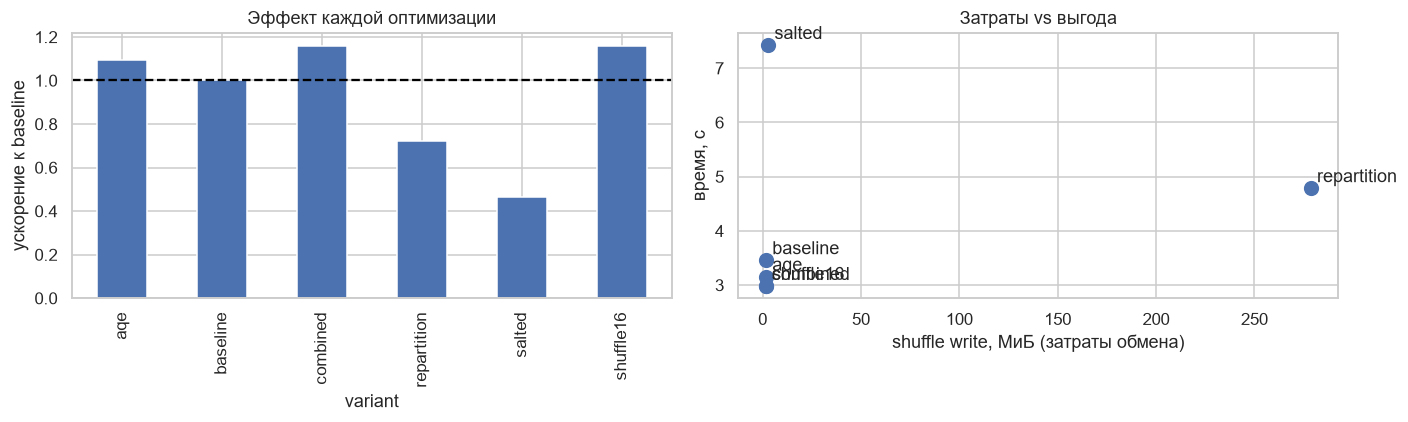

Лучшая измеренная конфигурация: combined
Это минимум среди проверенных вариантов, а не доказанный глобальный оптимум.


,параметр
spark.sql.shuffle.partitions,16
spark.sql.adaptive.enabled,true


Дополнительное преобразование: без salting/repartition
== Physical Plan ==
AdaptiveSparkPlan (12)
+- == Final Plan ==
   ResultQueryStage (8)
   +- * HashAggregate (7)
      +- AQEShuffleRead (6)
         +- ShuffleQueryStage (5), Statistics(sizeInBytes=3.9 MiB, rowCount=5.69E+4)
            +- Exchange (4)
               +- * HashAggregate (3)
                  +- * ColumnarToRow (2)
                     +- Scan parquet  (1)
+- == Initial Plan ==
   HashAggregate (11)
   +- Exchange (10)
      +- HashAggregate (9)
         +- Scan parquet  (1)


(1) Scan parquet 
Output [6]: [reg_code#7L, hour#8L, weekday#9L, dead_n#10L, injured_n#11L, vehicles_n#12L]
Batched: true
Location: InMemoryFileIndex [file:/C:/Users/Anton/Desktop/projects/Уник/2 курс/Современные технологии обработки больших данных/big_data/lab_02/_work/datasets/1GiB/part-0000.parquet, ... 89 entries]
ReadSchema: struct<reg_code:bigint,hour:bigint,weekday:bigint,dead_n:bigint,injured_n:bigint,vehicles_n:bigint>

(2) ColumnarTo

In [13]:
best_variant = show_optimizations(optimization, all_spark)

**Вывод.** С 16 partitions время сократилось примерно до 2,98 с. AQE поверх этой настройки почти ничего не изменил - разница в несколько миллисекунд слишком мала для вывода.

## Часть 6. CPU-трек A: Polars и DuckDB против Pandas

Беру замеры той же агрегации на 100 МиБ и 1 ГиБ. Всё выполняется на CPU, GPU в этой работе не использую.

In [14]:
show_cpu_comparison(summary)

seconds        peak_rss_mib           rss_delta_mib          
dataset  100MiB   1GiB       100MiB      1GiB        100MiB      1GiB
tool                                                                 
duckdb    0.043  0.293      115.656   149.305        15.535    48.934
pandas    0.135  1.115      381.906  3056.230       300.637  2974.820
polars    0.033  0.180      251.855   303.266       150.773   201.965

100MiB
  polars: 4.08x; снижение времени +75.5%
  duckdb: 3.17x; снижение времени +68.4%
1GiB
  polars: 6.19x; снижение времени +83.8%
  duckdb: 3.80x; снижение времени +73.7%


**Вывод.** Polars и DuckDB оказались быстрее Pandas. На таких коротких запросах переходить к GPU смысла нет: запуск и передача данных могут съесть весь выигрыш.

## Часть 7. Выбор инструмента и стоимость

Соберу рекомендации и прикину затраты. Тарифы, часы разработки и сопровождения задаю условно; настоящий кластер здесь не тестировал.

In [15]:
display(choice_matrix())
economics = estimate_cost(summary, large['rows'])
display(economics.round(4))
display(summary.xs('1GiB')[['seconds', 'startup_s', 'wall_including_startup_s']].round(3))

,условие,Pandas,Dask,Spark,Polars,DuckDB,рекомендация
0,"Данные помещаются в RAM, разовый анализ",+++,++,+,+++,+++,pandas / Polars / DuckDB
1,"Один узел, чтение с диска и SQL",++,++,+,+++,+++,DuckDB / Polars
2,"Больше RAM одного процесса, Python-пайплайн",+,+++,++,++,++,"Dask, после проверки spilling/разбиения"
3,"Десятки ГБ+, распределённый ETL и отказоустойч...",+,++,+++,++,++,"Spark, если нужен кластер"
4,Малые короткие запросы,+++,++,+,+++,+++,"CPU, без GPU"
5,"50 ГБ+, NVIDIA, поддерживаемые SQL-операции",+,++,+++,++,++,Spark + GPU только после измерений


,seconds,compute_RUB_run,million_rows_per_second,RUB_per_million_rows,development_hours,maintenance_hours_month,first_year_RUB
tool,,,,,,,
dask,1.5989,0.0089,13.9902,0.0004,8,2,48003.2423
duckdb,0.2931,0.0016,76.3133,0.0001,4,1,24000.5944
pandas,1.1147,0.0062,20.0682,0.0003,4,1,24002.2603
polars,0.1802,0.0010,124.1469,0.0000,5,1,25500.3654
spark,3.4558,0.0192,6.4731,0.0009,12,4,90007.0076


Для разового запуска дополнительно важно время запуска процесса/JVM:


,seconds,startup_s,wall_including_startup_s
tool,,,
dask,1.599,0.533,2.671
duckdb,0.293,0.041,0.816
pandas,1.115,0.005,1.664
polars,0.180,0.143,0.830
spark,3.456,7.219,11.746


Стоимость запроса считаю по времени обработки на уже запущенной машине. Если держать её включённой постоянно, при тарифе 20 ₽/час выйдет 175 200 ₽ в год - даже без нагрузки.

In [16]:
native_times = summary.xs('native').seconds
print(f'Реальная история: {cleaning["clean_rows"]:,} ДТП; '
      f'аналитическая проекция {table.nbytes/2**20:.1f} МиБ.')
print(f'Лучшее время на реальной истории: {native_times.idxmin()} = {native_times.min():.3f} с.')
print(f'Spark baseline на 1 ГиБ: {baseline_time:.3f} с; '
      f'лучший проверенный вариант {best_variant}: {optimization.loc[best_variant,"seconds"]:.3f} с.')
print('Проверены равенство результатов всех инструментов, GX и защитный лимит pandas.')

Реальная история: 1,738,125 ДТП; аналитическая проекция 79.6 МиБ.
Лучшее время на реальной истории: polars = 0.030 с.
Spark baseline на 1 ГиБ: 3.456 с; лучший проверенный вариант combined: 2.980 с.
Проверены равенство результатов всех инструментов, GX и защитный лимит pandas.


## Заключение

На 1 ГиБ получилось: Pandas - 1,115 с, Dask - 1,599 с, Spark - 3,456 с, Polars - 0,180 с, DuckDB - 0,293 с. Это результаты сохранённого прогона; после перезапуска числа могут отличаться.

Для текущих ДТП я бы оставил Parquet и Polars/DuckDB на одной машине. Spark пока добавляет больше сложности, чем пользы. Из его настроек помогло уменьшение числа partitions, а salting оказался лишним.